In [21]:
# https://sashamaps.net/docs/resources/20-colors/
DISTINCT_COLORS = [
    "#e6194B",
    "#3cb44b",
    "#ffe119",
    "#4363d8",
    "#f58231",
    "#911eb4",
    "#42d4f4",
    "#f032e6",
    "#bfef45",
    "#fabed4",
    "#469990",
    "#dcbeff",
    "#9A6324",
    "#fffac8",
    "#800000",
    "#aaffc3",
    "#808000",
    "#ffd8b1",
    "#000075",
    "#ffffff",
    "#000000",
]


In [22]:
from PIL import Image
import numpy as np 
def draw_seg_mask_color(image: Image.Image,segmask: np.ndarray, color=(255,255,0,100)):
    """
    Draw segmentation mask on the image by blending the image with the mask using a color
    Args:
        image (Image.Image): The input image.
        segmask (np.ndarray): The segmentation mask with shape (H, W).
    Returns:
        Image.Image: The image with the segmentation mask drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    
    # Create a new image with the same size as the input image
    mask_image = Image.new("RGBA", image.size, (0, 0, 0, 0))
    
    # Create a color mask with the specified color
    color_mask = Image.new("RGBA", image.size, color)
    
    # Convert the segmentation mask to a binary mask
    binary_mask = np.where(segmask > 0, 255, 0).astype(np.uint8)
    
    # Create a PIL image from the binary mask
    binary_mask_image = Image.fromarray(binary_mask, mode="L")
    
    # Paste the color mask onto the new image using the binary mask as a mask
    mask_image.paste(color_mask, (0, 0), binary_mask_image)
    
    # Blend the original image with the mask image
    blended_image = Image.alpha_composite(image, mask_image)
    
    return blended_image

#     


    

In [30]:
from PIL import Image, ImageDraw


import numpy as np 
def draw_seg_mask_blend(image: Image.Image,segmask: np.ndarray,alpha: float = 0.5) -> Image.Image:
    """
    Draw segmentation mask on the image by reducing the alpha  of the background
    Args:
        image (Image.Image): The input image.
        segmask (np.ndarray): The segmentation mask with shape (H, W).
    Returns:
        Image.Image: The image with the segmentation mask drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    # Convert the segmentation mask to a PIL image
    segmask = Image.fromarray(segmask.astype(np.uint8), mode="L")
    # Create a new image with the same size as the input image
    new_image = Image.new("RGBA", image.size, (0, 0, 0, 0))
    # Create a mask for the background
    background_mask = Image.new("L", image.size, 255)
    # Create a mask for the foreground
    foreground_mask = Image.new("L", image.size, 0)
    # Draw the segmentation mask on the foreground mask
    foreground_mask.paste(segmask, (0, 0), segmask)
    # Reduce the alpha of the background
    background_mask = Image.eval(background_mask, lambda x: int(x * alpha))
    # Paste the background and foreground masks on the new image
    new_image.paste(image, (0, 0), background_mask)
    new_image.paste(image, (0, 0), foreground_mask)
    # Convert the new image to RGB mode
    new_image = new_image.convert("RGB")
    # Convert the new image to a numpy array
    return new_image
#     


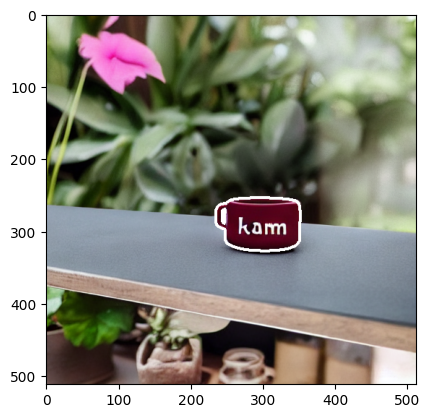

In [42]:
import skimage.measure

def draw_seg_mask_contour(image: Image.Image, segmask: np.ndarray, color=(255, 0, 0), thickness=1) -> Image.Image:
    """
    Draw segmentation mask contours on the image.
    
    Args:
        image (Image.Image): The input image.
        segmask (np.ndarray): The segmentation mask with shape (H, W).
        color (tuple): The color of the contour in RGB format.
        thickness (int): The thickness of the contour lines.
        
    Returns:
        Image.Image: The image with the segmentation mask contours drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    
    # Create a draw object
    draw = ImageDraw.Draw(image)
    
    # Find contours in the segmentation mask
    contours = skimage.measure.find_contours(segmask, 0.5)
    
    # Draw each contour
    for contour in contours:
        # Convert contour coordinates to integer
        contour = np.array(contour, dtype=np.int32)
        # flip x,y because skimage uses (row, col) format while PIL uses (x, y)
        contour[:, [0, 1]] = contour[:, [1, 0]]
        # Draw the contour on the image
        draw.line(list(map(tuple, contour)), fill=color, width=thickness)
    
    return image

image_path = "/home/tlips/Documents/diffusing-synthetic-data/data/coco/mugs/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/1dd9b373e3084cc0914a580ce5728cf8/002/ControlNetTXTFromDepthRenderer_ccs=1.5/Personalized ceramic mug with a full-color family photo and a matte finish on a terrarium table with a glass top and plants inside_0.png"
keypoints_path = "/home/tlips/Documents/diffusing-synthetic-data/data/scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/keypoints.json"
segmask_path = "/home/tlips/Documents/diffusing-synthetic-data/data/scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/segmentation.png"

image = Image.open(image_path)
segmask = np.array(Image.open(segmask_path).convert("L"))
# Draw segmentation mask with color
img = draw_seg_mask_contour(image, segmask, color=(255, 255, 255), thickness=4)

# show the image
plt.imshow(img)

In [24]:
def draw_keypoints(image: Image.Image, keypoints: np.ndarray, radius: int = 5) -> Image.Image:
    """
    Draw keypoints on the image.
    Args:
        image (Image.Image): The input image.
        keypoints (np.ndarray): The keypoints with shape (N, 2).
        radius (int): The radius of the keypoints.
    Returns:
        Image.Image: The image with the keypoints drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    
    draw = ImageDraw.Draw(image)
# Draw the keypoints on the image
    for i in range(keypoints.shape[0]):
        x, y = keypoints[i]
        # Draw a circle around the keypoint
        x, y = keypoints[i]
        # Draw a circle around the keypoint
        draw.ellipse((x - radius, y - radius, x + radius, y + radius), fill=DISTINCT_COLORS[i % len(DISTINCT_COLORS)])

    return image




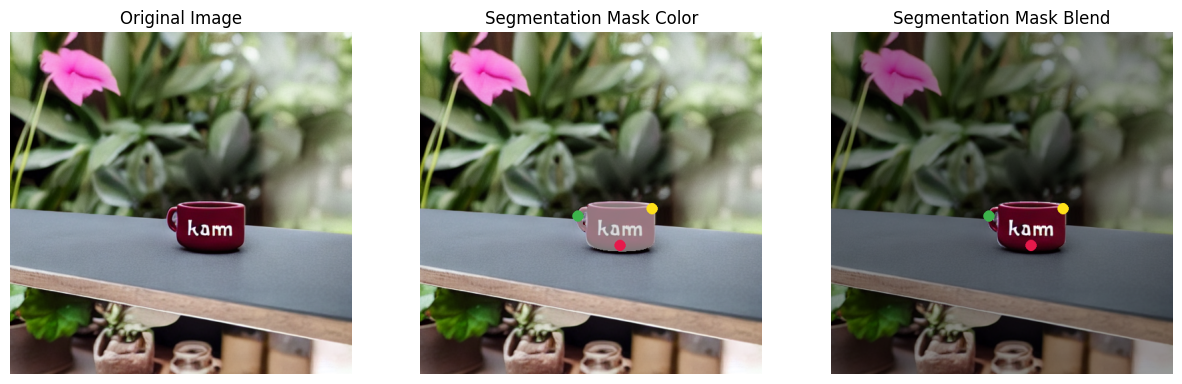

In [25]:
image_path = "/home/tlips/Documents/diffusing-synthetic-data/data/coco/mugs/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/1dd9b373e3084cc0914a580ce5728cf8/002/ControlNetTXTFromDepthRenderer_ccs=1.5/Personalized ceramic mug with a full-color family photo and a matte finish on a terrarium table with a glass top and plants inside_0.png"
keypoints_path = "/home/tlips/Documents/diffusing-synthetic-data/data/scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/keypoints.json"
segmask_path = "/home/tlips/Documents/diffusing-synthetic-data/data/scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/segmentation.png"


import json 
kp = json.load(open(keypoints_path))
keypoints = [val[:2] for val in kp.values()]
segmask = Image.open(segmask_path)
segmask = np.array(segmask)


image = Image.open(image_path)
image = image.convert("RGBA")

new_image = draw_seg_mask_color(image, segmask, color=(200, 200,200,150))

new_image2 = draw_seg_mask_blend(image, segmask, alpha=0.6)

# Draw keypoints on the image
keypoints = np.array(keypoints)
new_image = draw_keypoints(new_image, keypoints, radius=8)
new_image2 = draw_keypoints(new_image2, keypoints, radius=8)

import matplotlib.pyplot as plt

# plot original and both semgneatoin options side by side
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(image)
axs[0].set_title("Original Image")
axs[0].axis("off")
axs[1].imshow(new_image)
axs[1].set_title("Segmentation Mask Color")
axs[1].axis("off")
axs[2].imshow(new_image2)
axs[2].set_title("Segmentation Mask Blend")

axs[2].axis("off")
plt.show()

In [46]:
import dataclasses
from dsd import DATA_DIR

@dataclasses.dataclass
class ImageData:
    diffusion_image_path: str
    random_image_path: str
    scene_image_path: str
    keypoints_path: str
    segmask_path: str




def visualize_annotations(img_data: ImageData, seg_mask_alpha=True, seg_mask_contour=True) -> Image.Image:
    """
    Visualize the image, keypoints, and segmentation mask.
    Args:
        img_data (ImageData): The image data containing paths to the image, keypoints, and segmentation mask.
    Returns:
        Image.Image: The image with keypoints and segmentation mask drawn on it.
    """
    # Load the image
    scene_image = Image.open(img_data.scene_image_path).convert("RGBA")
    diffusion_image = Image.open(img_data.diffusion_image_path).convert("RGBA")
    random_image = Image.open(img_data.random_image_path).convert("RGBA")
    
    # Load the keypoints
    with open(img_data.keypoints_path, "r") as f:
        keypoints = json.load(f)
    
    # Convert keypoints to numpy array
    keypoints = np.array([val[:2] for val in keypoints.values()])
    
    # Load the segmentation mask
    segmask = Image.open(img_data.segmask_path)
    segmask = np.array(segmask)
    
    
    alpha_blend = 1.0
    keypoints_radius = 8
    segmask_color = (200, 200, 200, 200)

    if seg_mask_alpha:
        # Annotate the scene image with the segmentation mask and keypoints
        annotated_scene_image = draw_seg_mask_blend(scene_image, segmask, alpha=alpha_blend)
        annotated_diffusion_image = draw_seg_mask_blend(diffusion_image, segmask, alpha=alpha_blend)
        annotated_random_image = draw_seg_mask_blend(random_image, segmask, alpha=alpha_blend)
    else:
        # Annotate the scene image with the segmentation mask and keypoints
        annotated_scene_image = draw_seg_mask_color(scene_image, segmask, color=segmask_color)
        annotated_diffusion_image = draw_seg_mask_color(diffusion_image, segmask, color=segmask_color)
        annotated_random_image = draw_seg_mask_color(random_image, segmask, color=segmask_color)

    if seg_mask_contour:
        # Draw contours on the segmentation mask
        contour_color = (255,255,255)
        contourh_thickness = 5
        annotated_scene_image = draw_seg_mask_contour(annotated_scene_image, segmask, color=contour_color, thickness=contourh_thickness)
        annotated_diffusion_image = draw_seg_mask_contour(annotated_diffusion_image, segmask, color=contour_color, thickness=contourh_thickness)
        annotated_random_image = draw_seg_mask_contour(annotated_random_image, segmask, color=contour_color, thickness=contourh_thickness)


    annotated_scene_image = draw_keypoints(annotated_scene_image, keypoints, radius=keypoints_radius)
    annotated_diffusion_image = draw_keypoints(annotated_diffusion_image, keypoints, radius=keypoints_radius)
    annotated_random_image = draw_keypoints(annotated_random_image, keypoints, radius=keypoints_radius)

    return annotated_scene_image, annotated_diffusion_image, annotated_random_image





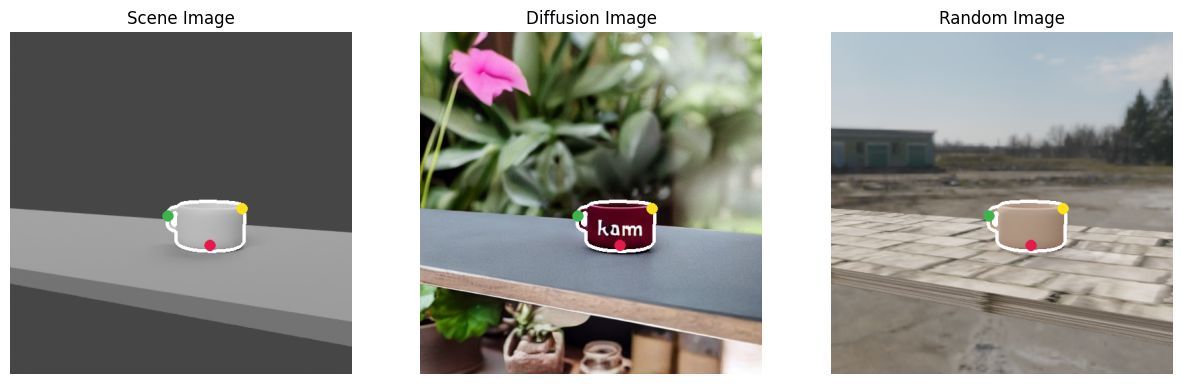

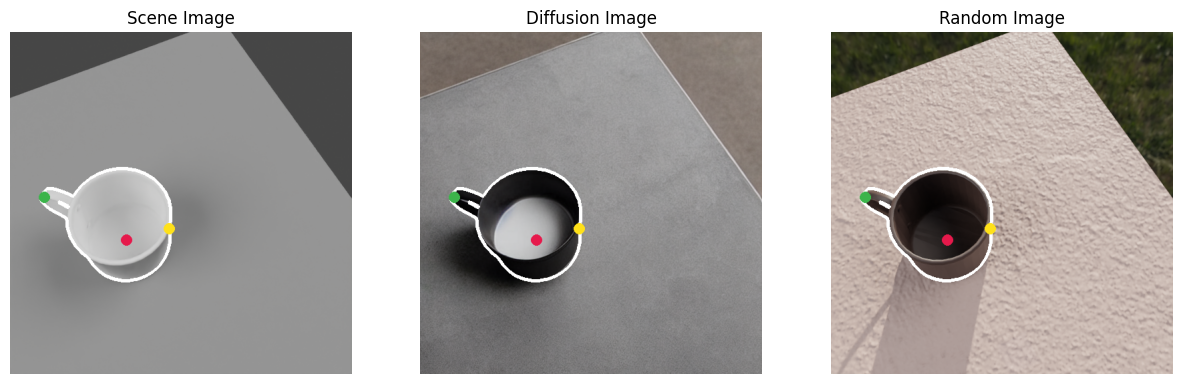

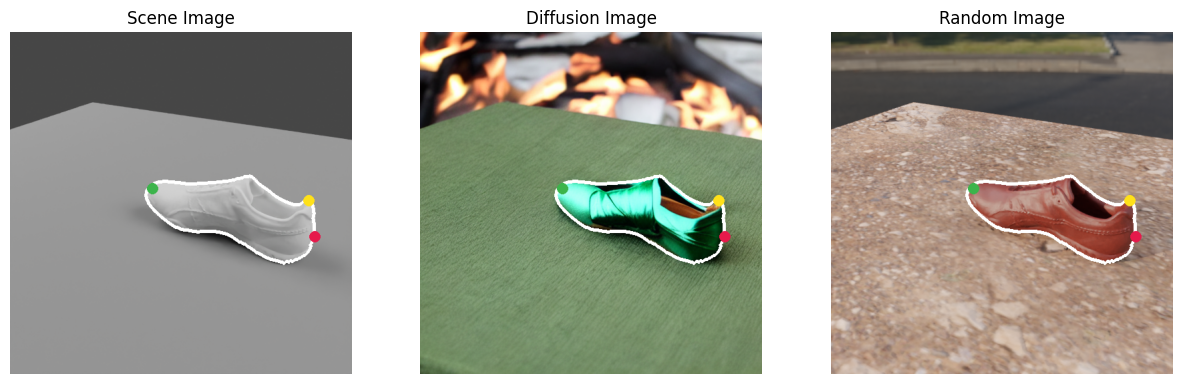

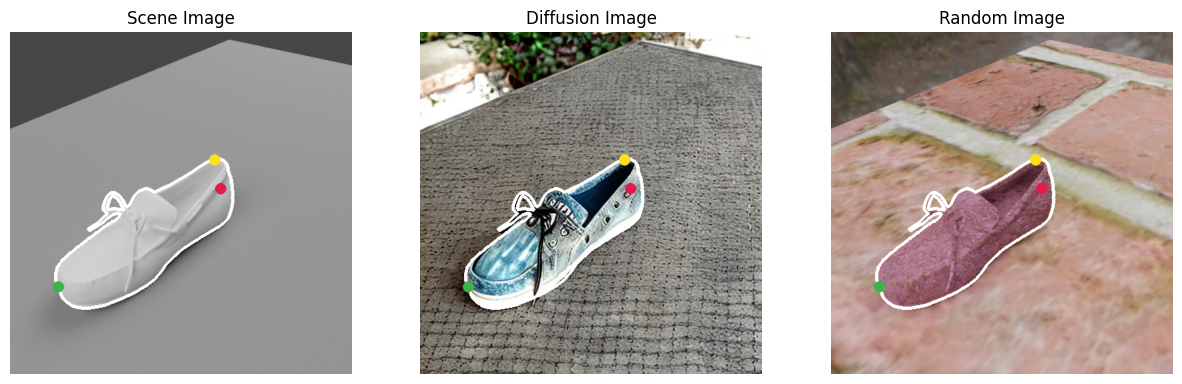

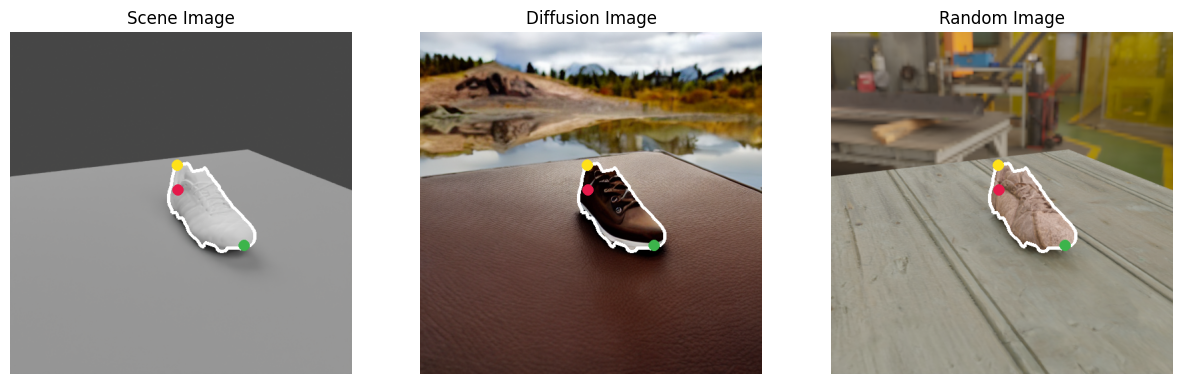

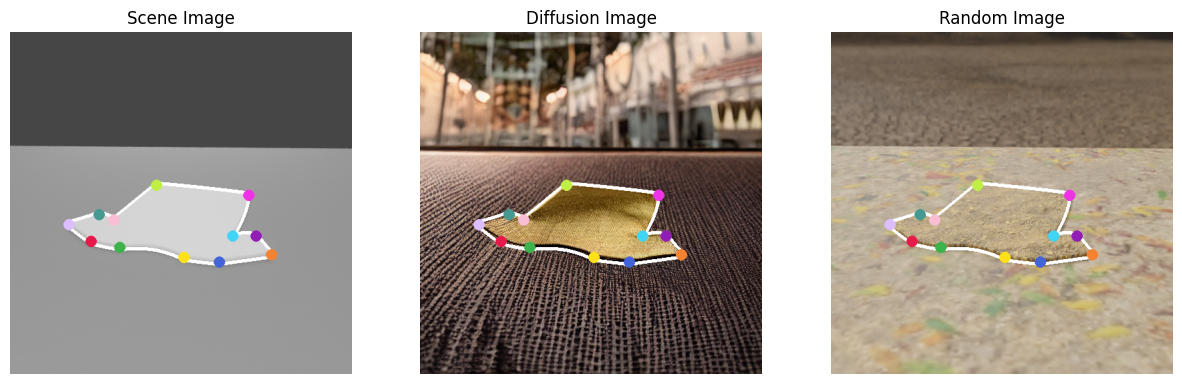

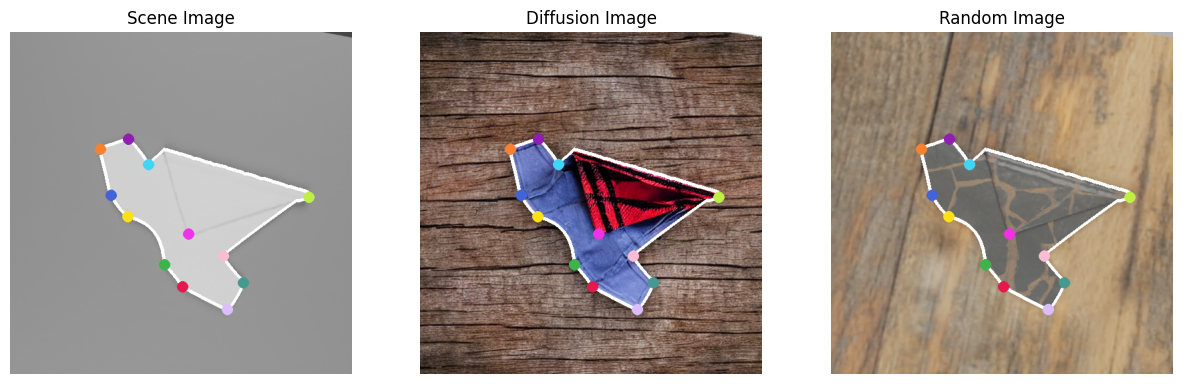

In [47]:

mug_example_1 = ImageData(
    scene_image_path= DATA_DIR  /"scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/rgb.png",
    diffusion_image_path= DATA_DIR  /"coco/mugs/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/1dd9b373e3084cc0914a580ce5728cf8/002/ControlNetTXTFromDepthRenderer_ccs=1.5/Personalized ceramic mug with a full-color family photo and a matte finish on a terrarium table with a glass top and plants inside_0.png",
    random_image_path= DATA_DIR / "coco/mugs/random_textures/images/1dd9b373e3084cc0914a580ce5728cf8/002/random_textures/rgb_0.png",
    keypoints_path=DATA_DIR  /"scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/keypoints.json",
    segmask_path=DATA_DIR  /"scenes/mugs/objaverse-filtered-2500-ral/1dd9b373e3084cc0914a580ce5728cf8/002/segmentation.png",

)

mug_example_2 = ImageData(
    diffusion_image_path= DATA_DIR / "coco/mugs/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/7bc2b14a48d1413e9375c32a53e3ee6f/016/ControlNetTXTFromDepthRenderer_ccs=1.5/Matte ceramic mug with a minimalist geometric design in black and white on a table built from reclaimed pallets_0.png",
    random_image_path= DATA_DIR / "coco/mugs/random_textures/images/7bc2b14a48d1413e9375c32a53e3ee6f/016/random_textures/rgb_0.png",
    scene_image_path= DATA_DIR /"scenes/mugs/objaverse-filtered-2500-ral/7bc2b14a48d1413e9375c32a53e3ee6f/016/rgb.png",
    keypoints_path=DATA_DIR  /"scenes/mugs/objaverse-filtered-2500-ral/7bc2b14a48d1413e9375c32a53e3ee6f/016/keypoints.json",
    segmask_path=DATA_DIR  /"scenes/mugs/objaverse-filtered-2500-ral/7bc2b14a48d1413e9375c32a53e3ee6f/016/segmentation.png",
)

shoe_example_1 = ImageData(
    diffusion_image_path = DATA_DIR / "coco/shoes/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/ASICS_GELDirt_Dog_4_SunFlameBlack/006/ControlNetTXTFromDepthRenderer_ccs=1.5/Emerald green satin ballet flats with a dainty bow on a table with a built-in fire pit for warmth_0.png",
    random_image_path = DATA_DIR / "coco/shoes/random_textures/images/ASICS_GELDirt_Dog_4_SunFlameBlack/006/random_textures/rgb_0.png",
    scene_image_path = DATA_DIR / "scenes/shoes/gso-filtered-2500/ASICS_GELDirt_Dog_4_SunFlameBlack/006/rgb.png",
    keypoints_path = DATA_DIR / "scenes/shoes/gso-filtered-2500/ASICS_GELDirt_Dog_4_SunFlameBlack/006/keypoints.json",
    segmask_path = DATA_DIR / "scenes/shoes/gso-filtered-2500/ASICS_GELDirt_Dog_4_SunFlameBlack/006/segmentation.png",
)

shoe_example_2 = ImageData(
    diffusion_image_path= DATA_DIR / "coco/shoes/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/Mens_Billfish_Slip_On_in_Coffee_nK6AJJAHOae/009/ControlNetTXTFromDepthRenderer_ccs=1.5/Acid wash denim fabric sneakers with a lace-up closure on a table with a bird bath fountain_0.png",
    random_image_path= DATA_DIR / "coco/shoes/random_textures/images/Mens_Billfish_Slip_On_in_Coffee_nK6AJJAHOae/009/random_textures/rgb_0.png",
    scene_image_path= DATA_DIR / "scenes/shoes/gso-filtered-2500/Mens_Billfish_Slip_On_in_Coffee_nK6AJJAHOae/009/rgb.png",
    keypoints_path=DATA_DIR / "scenes/shoes/gso-filtered-2500/Mens_Billfish_Slip_On_in_Coffee_nK6AJJAHOae/009/keypoints.json",
    segmask_path=DATA_DIR / "scenes/shoes/gso-filtered-2500/Mens_Billfish_Slip_On_in_Coffee_nK6AJJAHOae/009/segmentation.png",
)

shoe_example_3 = ImageData(
    diffusion_image_path=  DATA_DIR / "coco/shoes/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/11pro_SL_TRX_FG/009/ControlNetTXTFromDepthRenderer_ccs=1.5/Brown leather hiking boots with a lug sole and a waterproof membrane on a table with an air purifier_0.png",
    random_image_path= DATA_DIR / "coco/shoes/random_textures/images/11pro_SL_TRX_FG/009/random_textures/rgb_1.png",
    scene_image_path= DATA_DIR / "scenes/shoes/gso-filtered-2500/11pro_SL_TRX_FG/009/rgb.png",
    keypoints_path=DATA_DIR / "scenes/shoes/gso-filtered-2500/11pro_SL_TRX_FG/009/keypoints.json",
    segmask_path=DATA_DIR / "scenes/shoes/gso-filtered-2500/11pro_SL_TRX_FG/009/segmentation.png",
)

tshirt_example_1 = ImageData(
    diffusion_image_path= DATA_DIR / "coco/tshirts/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/000026/000/ControlNetTXTFromDepthRenderer_ccs=1.5/Gold metallic thread embroidered T-shirt with a V-neck on a table with a built-in bottle opener_0.png",
    random_image_path= DATA_DIR / "coco/tshirts/random_textures/images/000026/000/random_textures/rgb_0.png",
    scene_image_path= DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000026/000/rgb.png",
    keypoints_path=DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000026/000/keypoints.json",
    segmask_path=DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000026/000/segmentation.png",
)

tshirt_example_2 = ImageData(
    diffusion_image_path= DATA_DIR / "coco/tshirts/diffusion_renders/02-gemini-prompts/ControlNetTXTFromDepthRenderer_ccs=1.5/images/000048/005/ControlNetTXTFromDepthRenderer_ccs=1.5/A bold red and blue plaid flannel shirt, perfect for layering over a basic tee. on a table with a bird feeder camera_0.png",
    random_image_path= DATA_DIR / "coco/tshirts/random_textures/images/000048/005/random_textures/rgb_0.png",
    scene_image_path= DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000048/005/rgb.png",
    keypoints_path=DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000048/005/keypoints.json",
    segmask_path=DATA_DIR / "scenes/tshirts/syncloth-filtered-2500/000048/005/segmentation.png",
)

def visualize(example: ImageData):
    scene, diffusion, random = visualize_annotations(example)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(scene)
    axs[0].set_title("Scene Image") 
    axs[0].axis("off")
    axs[1].imshow(diffusion)
    axs[1].set_title("Diffusion Image")
    axs[1].axis("off")
    axs[2].imshow(random)
    axs[2].set_title("Random Image")
    axs[2].axis("off")
    plt.show()

visualize(mug_example_1)
visualize(mug_example_2)
visualize(shoe_example_1)
visualize(shoe_example_2)
visualize(shoe_example_3)
visualize(tshirt_example_1)
visualize(tshirt_example_2)

(-0.5, 3071.5, 1535.5, -0.5)

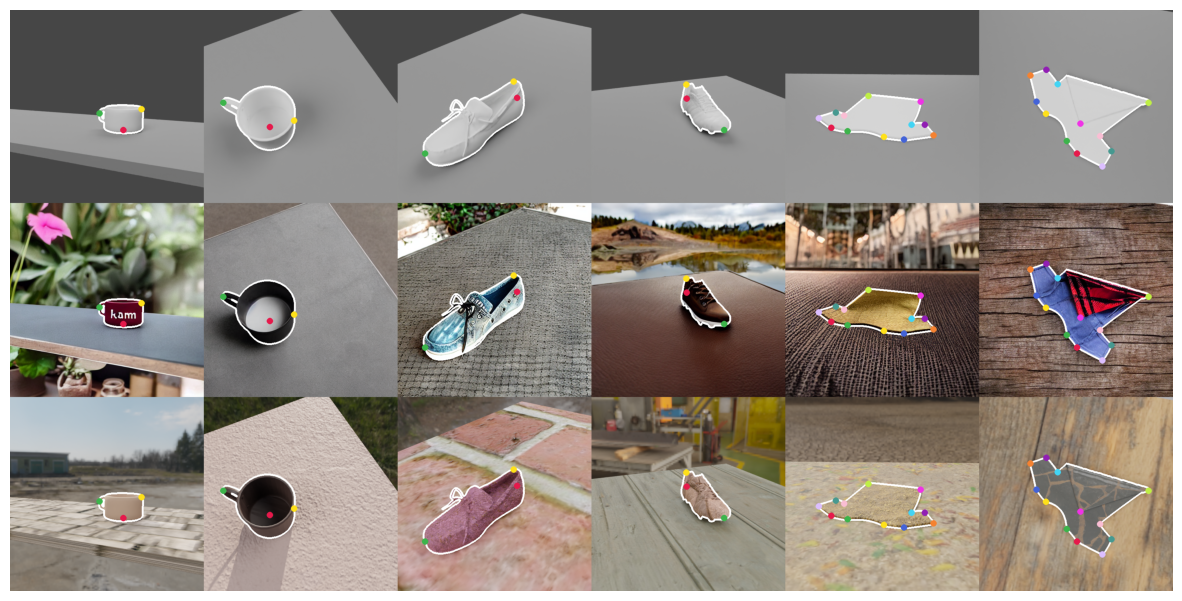

In [48]:
# create a single image with all the examples

# this image has 3 rows, original, diffusion, random
# and concatenates all the examples horizontally

def create_example_image(examples: list[ImageData], seg_mask_alpha=True) -> Image.Image:
    """
    Create a single image with all the examples.
    Args:
        examples (list[ImageData]): The list of image data containing paths to the image, keypoints, and segmentation mask.
    Returns:
        Image.Image: The image with all the examples drawn on it.
    """
    # Load the images
    scene_images = []
    diffusion_images = []
    random_images = []
    
    for example in examples:
        scene_image, diffusion_image, random_image = visualize_annotations(example, seg_mask_alpha=seg_mask_alpha)
        scene_images.append(scene_image)
        diffusion_images.append(diffusion_image)
        random_images.append(random_image)
    # Concatenate the images horizontally
    scene_image = Image.new("RGBA", (scene_images[0].width * len(scene_images), scene_images[0].height))
    diffusion_image = Image.new("RGBA", (diffusion_images[0].width * len(diffusion_images), diffusion_images[0].height))
    random_image = Image.new("RGBA", (random_images[0].width * len(random_images), random_images[0].height))
    for i in range(len(scene_images)):
        scene_image.paste(scene_images[i], (i * scene_images[i].width, 0))
        diffusion_image.paste(diffusion_images[i], (i * diffusion_images[i].width, 0))
        random_image.paste(random_images[i], (i * random_images[i].width, 0))

    # Create a new image with the same size as the input image

    new_image = Image.new("RGBA", (scene_image.width, scene_image.height * 3), (255, 255, 255, 255))
    # Paste the images on the new image
    new_image.paste(scene_image, (0, 0))
    new_image.paste(diffusion_image, (0, scene_image.height))
    new_image.paste(random_image, (0, scene_image.height * 2))
    # Convert the new image to RGB mode
    new_image = new_image.convert("RGB")
    return new_image

examples = [
    mug_example_1,
    mug_example_2,
    #shoe_example_1,
    shoe_example_2,
    shoe_example_3,
    tshirt_example_1,
    tshirt_example_2,
]
example_image = create_example_image(examples, seg_mask_alpha=True)

plt.figure(figsize=(15, 15))
plt.imshow(example_image)
plt.axis("off")

In [29]:

example_image.save("../../visualisations/example_renders.png", dpi=(300, 300))

## Model Inference


In [120]:
image_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/scp/tshirts/tshirts-test-kpcentercropped/test/location_4/tshirts/2023-04-24_14-51-30_rgb_zed.png"

keypoint_model_artifact = ""
seg_model_artifact = "tlips/dsd-paper-yolo/runs/5v57ni2p"